# Heart Disease Prediction
Predicting heart disease presence from clinical features using the UCI Heart Disease dataset (Kaggle).
Models compared: Logistic Regression, Random Forest, XGBoost.

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("heart_disease_uci.csv")
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [52]:
df.describe

<bound method NDFrame.describe of       id  age     sex        dataset               cp  trestbps   chol    fbs  \
0      1   63    Male      Cleveland   typical angina     145.0  233.0   True   
1      2   67    Male      Cleveland     asymptomatic     160.0  286.0  False   
2      3   67    Male      Cleveland     asymptomatic     120.0  229.0  False   
3      4   37    Male      Cleveland      non-anginal     130.0  250.0  False   
4      5   41  Female      Cleveland  atypical angina     130.0  204.0  False   
..   ...  ...     ...            ...              ...       ...    ...    ...   
915  916   54  Female  VA Long Beach     asymptomatic     127.0  333.0   True   
916  917   62    Male  VA Long Beach   typical angina       NaN  139.0  False   
917  918   55    Male  VA Long Beach     asymptomatic     122.0  223.0   True   
918  919   58    Male  VA Long Beach     asymptomatic       NaN  385.0   True   
919  920   62    Male  VA Long Beach  atypical angina     120.0  254.0  Fal

In [53]:
df.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

In [54]:
df.dtypes

id            int64
age           int64
sex             str
dataset         str
cp              str
trestbps    float64
chol        float64
fbs          object
restecg         str
thalch      float64
exang        object
oldpeak     float64
slope           str
ca          float64
thal            str
num           int64
dtype: object

In [55]:
df['trestbps'] = df['trestbps'].fillna(df['trestbps'].median)
df['chol'] = df['chol'].fillna(df['chol'].median)
df['thalch'] = df['thalch'].fillna(df['thalch'].median)
df['oldpeak'] = df['oldpeak'].fillna(df['oldpeak'].median)
df['ca'] = df['ca'].fillna(df['ca'].median)
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [56]:
df.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps      0
chol          0
fbs          90
restecg       2
thalch        0
exang        55
oldpeak       0
slope       309
ca            0
thal        486
num           0
dtype: int64

In [57]:
df.head(20)

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
5,6,56,Male,Cleveland,atypical angina,120.0,236.0,False,normal,178.0,False,0.8,upsloping,0.0,normal,0
6,7,62,Female,Cleveland,asymptomatic,140.0,268.0,False,lv hypertrophy,160.0,False,3.6,downsloping,2.0,normal,3
7,8,57,Female,Cleveland,asymptomatic,120.0,354.0,False,normal,163.0,True,0.6,upsloping,0.0,normal,0
8,9,63,Male,Cleveland,asymptomatic,130.0,254.0,False,lv hypertrophy,147.0,False,1.4,flat,1.0,reversable defect,2
9,10,53,Male,Cleveland,asymptomatic,140.0,203.0,True,lv hypertrophy,155.0,True,3.1,downsloping,0.0,reversable defect,1


In [58]:
df.dtypes


id           int64
age          int64
sex            str
dataset        str
cp             str
trestbps    object
chol        object
fbs         object
restecg        str
thalch      object
exang       object
oldpeak     object
slope          str
ca          object
thal           str
num          int64
dtype: object

In [59]:
df.chol = pd.to_numeric(df["chol"], errors="coerce")
df.trestbps = pd.to_numeric(df["trestbps"], errors = "coerce")

In [60]:
df.dtypes

id            int64
age           int64
sex             str
dataset         str
cp              str
trestbps    float64
chol        float64
fbs          object
restecg         str
thalch       object
exang        object
oldpeak      object
slope           str
ca           object
thal            str
num           int64
dtype: object

In [61]:
df.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch        0
exang        55
oldpeak       0
slope       309
ca            0
thal        486
num           0
dtype: int64

In [62]:
df['trestbps'] = df['trestbps'].fillna(df['trestbps'].median)
df['chol'] = df['chol'].fillna(df['chol'].median)


In [63]:
df.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps      0
chol          0
fbs          90
restecg       2
thalch        0
exang        55
oldpeak       0
slope       309
ca            0
thal        486
num           0
dtype: int64

In [64]:
for col in ["trestbps", "chol", "thalch", "oldpeak", "ca"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [65]:
df.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

In [66]:
df["trestbps"] = df["trestbps"].fillna(df["trestbps"].median())
df["chol"] = df["chol"].fillna(df["chol"].median())
df["thalch"] = df["thalch"].fillna(df["thalch"].median())
df["oldpeak"] = df["oldpeak"].fillna(df["oldpeak"].median())

In [67]:
df.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps      0
chol          0
fbs          90
restecg       2
thalch        0
exang        55
oldpeak       0
slope       309
ca          611
thal        486
num           0
dtype: int64

In [68]:
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [69]:
df = df.drop(columns=["ca", "id"])

In [70]:
print("chol zeros:", (df["chol"] == 0).sum())
print("trestbps zeros:", (df["trestbps"] == 0).sum())


chol zeros: 172
trestbps zeros: 1


In [85]:
df["trestbps"] = df["trestbps"].replace(0,np.nan)
df["chol"] = df["chol"].replace(0, np.nan)


In [72]:
df["chol"] = df["chol"].fillna(df["chol"].median())
df["trestbps"] = df["trestbps"].fillna(df["trestbps"].median())
#cleaning the numeric columns, zeros to nan then filling them with median

In [73]:
print("chol zeros:", (df["chol"] == 0).sum())
print("trestbps zeros:", (df["trestbps"] == 0).sum())
print(df[["chol", "trestbps"]].describe())

chol zeros: 0
trestbps zeros: 0
             chol    trestbps
count  920.000000  920.000000
mean   244.030435  132.136957
std     52.010955   17.929761
min     85.000000   80.000000
25%    217.750000  120.000000
50%    236.000000  130.000000
75%    267.000000  140.000000
max    603.000000  200.000000


In [74]:
df.isnull().sum()

age           0
sex           0
dataset       0
cp            0
trestbps      0
chol          0
fbs          90
restecg       2
thalch        0
exang        55
oldpeak       0
slope       309
thal        486
num           0
dtype: int64

In [88]:
for col in ["thal", "slope"]:
    df[col] = df[col].fillna("missing")

for col in ["fbs", "exang", "restecg"]:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum().sum(), df.shape)
print(df.dtypes)
#clean the categorical columns

0 (920, 14)
age           int64
sex             str
dataset         str
cp              str
trestbps    float64
chol        float64
fbs          object
restecg         str
thalch      float64
exang        object
oldpeak     float64
slope           str
thal            str
target        int64
dtype: object


In [76]:
df["target"] = (df["num"] > 0).astype(int) #is num greater than 0,converts True to 1 and False to 0
df = df.drop(columns=["num"])   # num column is deleted

print(df["target"].value_counts()) #shows how many rows are 0 and how many are 1
print(df["target"].value_counts(normalize=True).round(3))


target
1    509
0    411
Name: count, dtype: int64
target
1    0.553
0    0.447
Name: proportion, dtype: float64


In [90]:
df.isnull().sum()

age         0
sex         0
dataset     0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
thal        0
target      0
dtype: int64

In [93]:
df.columns

Index(['age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
       'thalch', 'exang', 'oldpeak', 'slope', 'thal', 'target'],
      dtype='str')

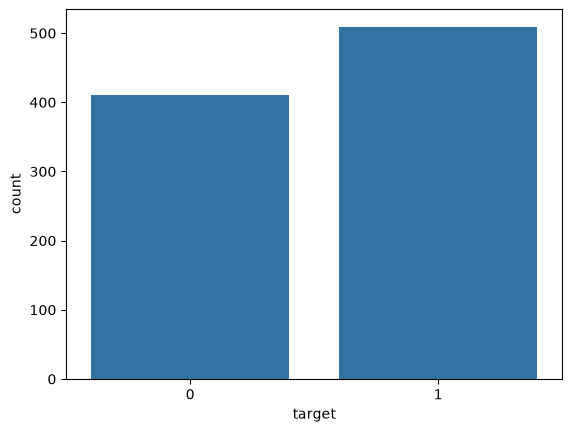

In [89]:
sns.countplot(data=df, x="target"); plt.show()

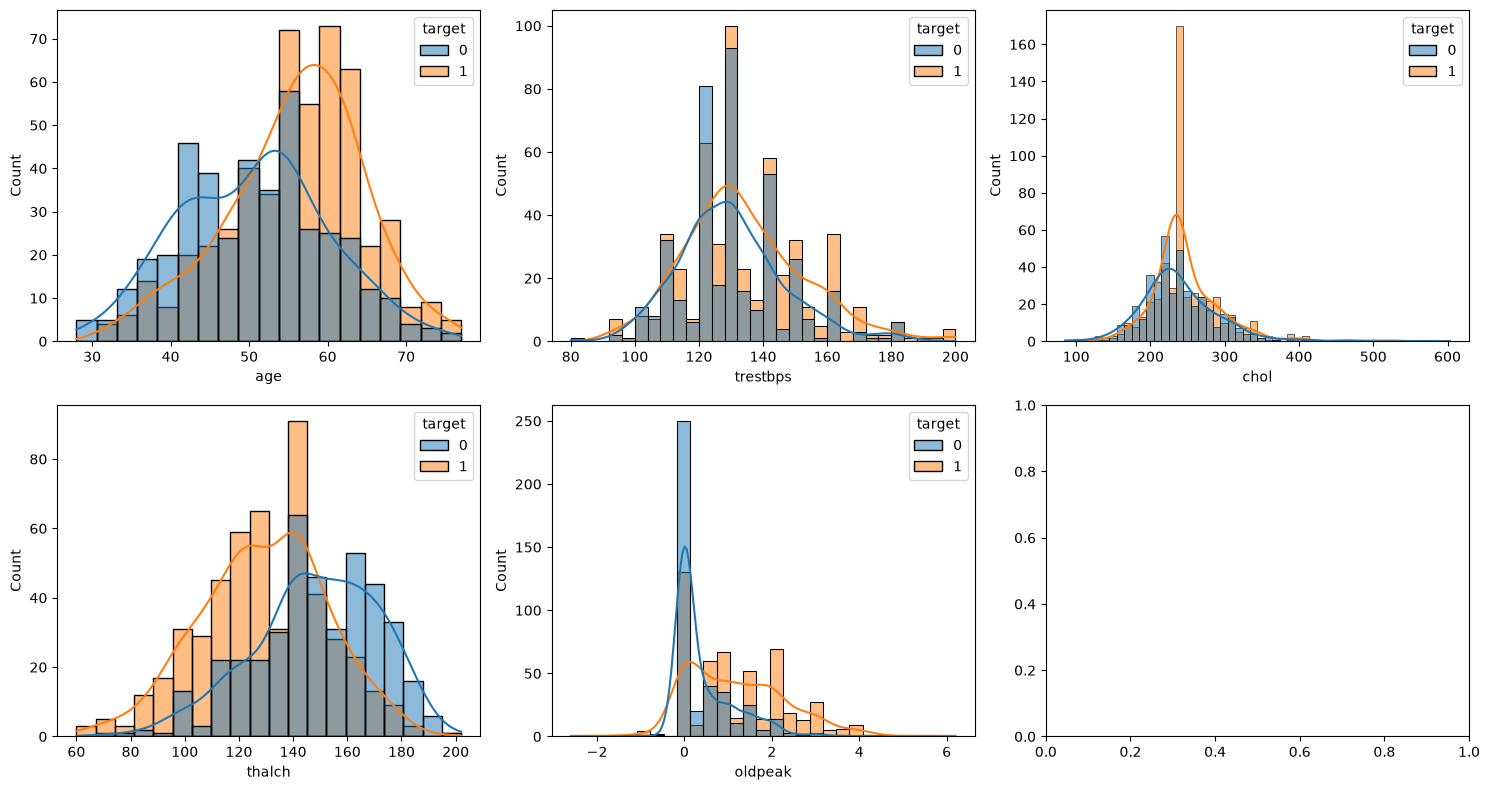

In [82]:
num_cols = ["age", "trestbps", "chol", "thalch", "oldpeak"] #numeric features vs target
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=col, hue="target", kde=True, ax=ax)
plt.tight_layout(); plt.show()

## Numeric Features vs Target

**Target:** 0 = no heart disease, 1 = heart disease

### Observations

- **Age:** Patients with heart disease are generally older. The no-disease group peaks around 50-55 years, and the disease group peaks around 58-62. There is a lot of overlap, so age is a moderate predictor.
- **thalch (max heart rate):** This shows the clearest separation. Patients without disease reach a higher max heart rate (about 140-170), while patients with disease cluster lower (about 100-140). Lower max heart rate is linked to disease.
- **oldpeak (ST depression):** Most patients without disease have an oldpeak of 0. Patients with disease have higher and more spread-out values. Higher ST depression is linked to disease.
- **trestbps (resting blood pressure):** The two groups overlap almost completely, so this is a weak feature on its own.
- **chol (cholesterol):** There is a sharp spike near the median. This is an artifact of replacing impossible zeros (172 rows) and missing values with the median. Cholesterol in this dataset is partly imputed, so it should not be treated as a reliable signal.

### Takeaway

`thalch` and `oldpeak` look like the strongest numeric features, followed by `age`. `trestbps` and `chol` are weak or unreliable. These are associations in the data, not proof of cause.

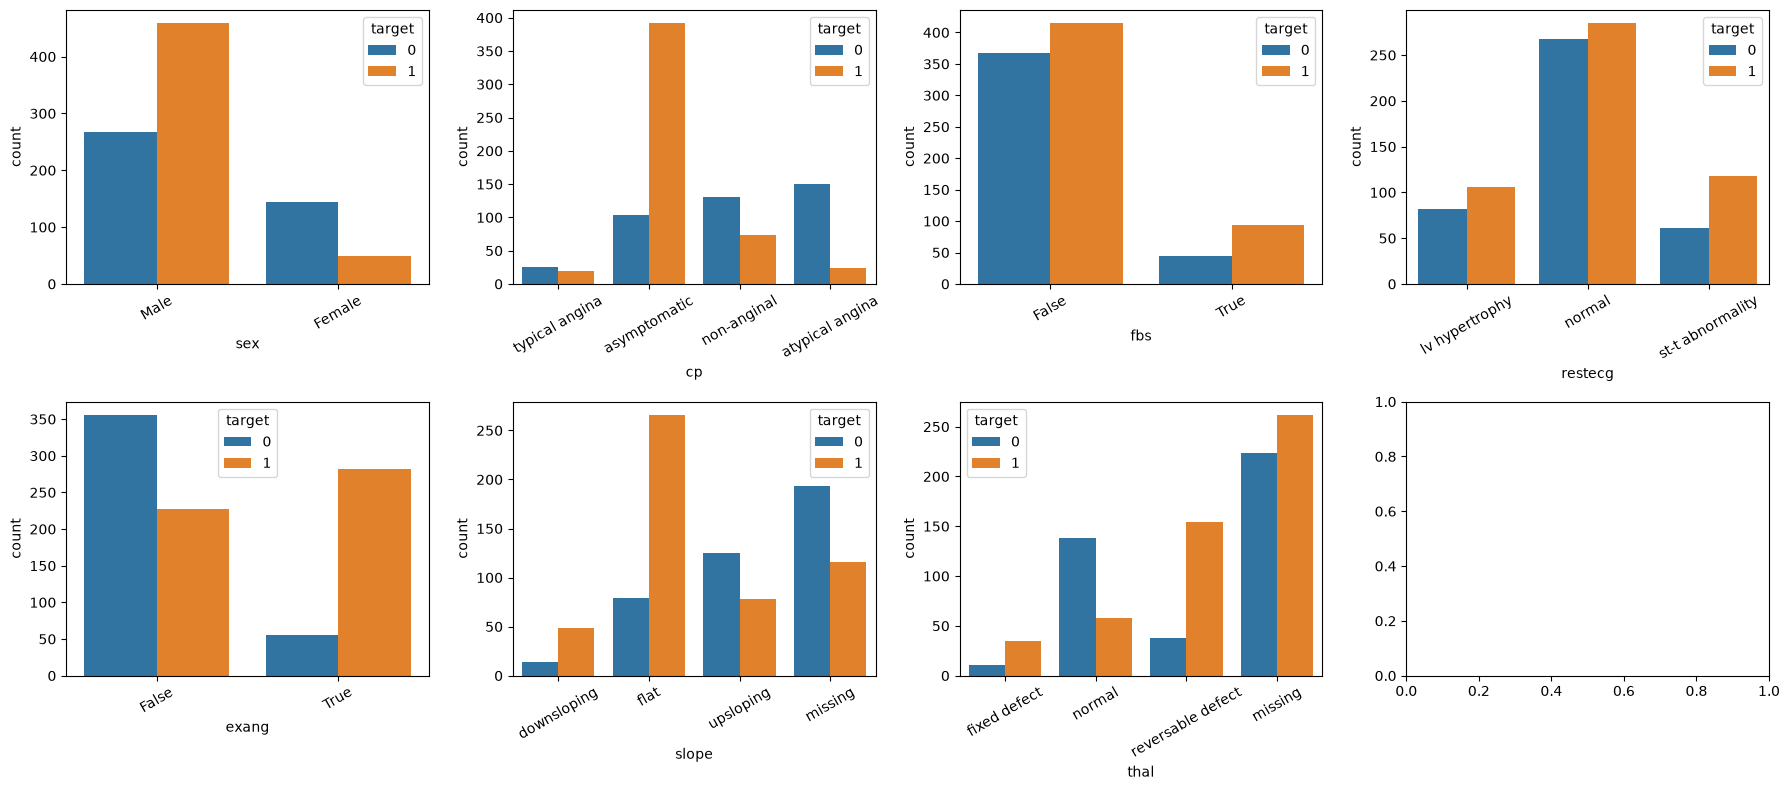

In [83]:
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"] #categorical features vs target
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(data=df, x=col, hue="target", ax=ax)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## Categorical Features vs Target

### Observations

- **cp (chest pain type):** Asymptomatic chest pain has by far the most disease cases. The other pain types are mostly in the no-disease group. This is one of the strongest categorical features.
- **exang (exercise-induced angina):** Patients with exercise-induced angina are much more likely to have heart disease.
- **thal:** Reversible defect is strongly linked to disease, and a normal result leans toward no disease. About half of the thal values were missing and were grouped into a "missing" category.
- **slope:** A flat ST slope is linked to disease, while an upsloping slope leans toward no disease. A large share of values were missing and labeled "missing".
- **sex:** Males show a much higher share of disease than females, but the dataset contains far more males than females, so this may not generalize.
- **fbs and restecg:** Both look similar across the two classes and are weak predictors.

### Takeaway

`cp`, `exang`, `thal` and `slope` are the strongest categorical features. `fbs` and `restecg` add little. The "missing" categories in `thal` and `slope` mostly come from the non-Cleveland hospitals, so the model may partly pick up on data source and not only on medical signal.

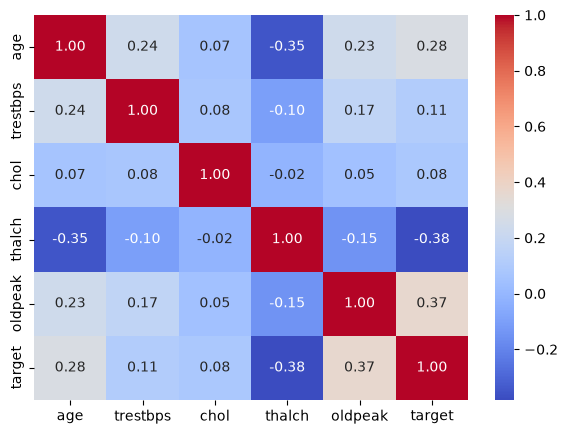

In [84]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols + ["target"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

## Correlation Heatmap

### Observations

- **thalch** has the strongest correlation with the target (-0.38): lower max heart rate goes with heart disease.
- **oldpeak** is next (0.37): higher ST depression goes with heart disease.
- **age** has a moderate correlation (0.28).
- **trestbps** (0.11) and **chol** (0.08) are only weakly correlated with the target. The chol value is also affected by median imputation.
- The strongest relationship between two features is age vs thalch (-0.35). No pair is above 0.4, so multicollinearity is not a concern.

### Takeaway

`thalch`, `oldpeak` and `age` are the most useful numeric predictors. The heatmap covers only numeric features and linear relationships, so the categorical features (cp, exang, thal, slope) need to be judged from the earlier count plots.

In [95]:
X = df.drop(columns = ["target", "dataset"])
Y = df["target"]
print(X.shape, Y.shape)

(920, 12) (920,)


In [100]:
X = pd.get_dummies(X, drop_first=True)  #drops one category per column
print(X.shape)
X.head()


(920, 19)


,age,trestbps,chol,thalch,oldpeak,sex_Male,cp_atypical angina,cp_non-anginal,cp_typical angina,fbs_True,restecg_normal,restecg_st-t abnormality,exang_True,slope_flat,slope_missing,slope_upsloping,thal_missing,thal_normal,thal_reversable defect
0,63,145.0,233.0,150.0,2.3,True,False,False,True,True,False,False,False,False,False,False,False,False,False
1,67,160.0,286.0,108.0,1.5,True,False,False,False,False,False,False,True,True,False,False,False,True,False
2,67,120.0,229.0,129.0,2.6,True,False,False,False,False,False,False,True,True,False,False,False,False,True
3,37,130.0,250.0,187.0,3.5,True,False,True,False,False,True,False,False,False,False,False,False,True,False
4,41,130.0,204.0,172.0,1.4,False,True,False,False,False,False,False,False,False,False,True,False,True,False


In [105]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, stratify=Y, random_state=42
)
print(X_train.shape, X_test.shape)
print(Y_train.value_counts(normalize=True).round(3))
print(Y_test.value_counts(normalize=True).round(3))

(736, 19) (184, 19)
target
1    0.553
0    0.447
Name: proportion, dtype: float64
target
1    0.554
0    0.446
Name: proportion, dtype: float64


In [106]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

auc = cross_val_score(logreg, X_train, Y_train, cv=cv, scoring="roc_auc")
rec = cross_val_score(logreg, X_train, Y_train, cv=cv, scoring="recall")
acc = cross_val_score(logreg, X_train, Y_train, cv=cv, scoring="accuracy")

print(f"Accuracy: {acc.mean():.3f}")
print(f"ROC-AUC:  {auc.mean():.3f} (+/- {auc.std():.3f})")
print(f"Recall:   {rec.mean():.3f}")

Accuracy: 0.806
ROC-AUC:  0.875 (+/- 0.022)
Recall:   0.843


In [107]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

logreg.fit(X_train, Y_train)
pred = logreg.predict(X_test)
proba = logreg.predict_proba(X_test)[:, 1]

print(classification_report(Y_test, pred))
print("ROC-AUC:", round(roc_auc_score(Y_test, proba), 3))
print(confusion_matrix(Y_test, pred))

              precision    recall  f1-score   support

           0       0.84      0.76      0.79        82
           1       0.82      0.88      0.85       102

    accuracy                           0.83       184
   macro avg       0.83      0.82      0.82       184
weighted avg       0.83      0.83      0.82       184

ROC-AUC: 0.902
[[62 20]
 [12 90]]


In [108]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, random_state=42)

auc = cross_val_score(rf, X_train, Y_train, cv=cv, scoring="roc_auc")
rec = cross_val_score(rf, X_train, Y_train, cv=cv, scoring="recall")
acc = cross_val_score(rf, X_train, Y_train, cv=cv, scoring="accuracy")

print(f"Accuracy: {acc.mean():.3f}")
print(f"ROC-AUC:  {auc.mean():.3f} (+/- {auc.std():.3f})")
print(f"Recall:   {rec.mean():.3f}")

Accuracy: 0.813
ROC-AUC:  0.871 (+/- 0.029)
Recall:   0.862


In [109]:
rf.fit(X_train, Y_train)
pred_rf = rf.predict(X_test)
proba_rf = rf.predict_proba(X_test)[:, 1]

print(classification_report(Y_test, pred_rf))
print("ROC-AUC:", round(roc_auc_score(Y_test, proba_rf), 3))
print(confusion_matrix(Y_test, pred_rf))

              precision    recall  f1-score   support

           0       0.82      0.79      0.81        82
           1       0.84      0.86      0.85       102

    accuracy                           0.83       184
   macro avg       0.83      0.83      0.83       184
weighted avg       0.83      0.83      0.83       184

ROC-AUC: 0.9
[[65 17]
 [14 88]]


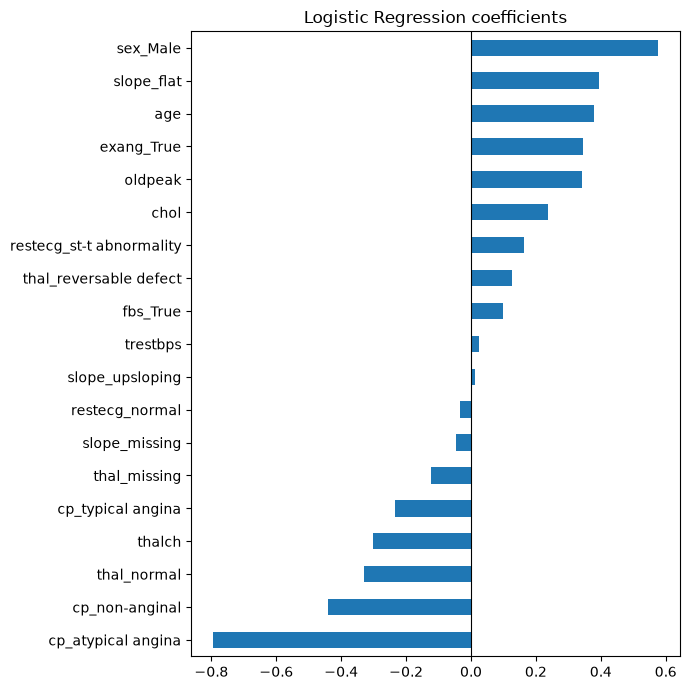

In [110]:
coefs = pd.Series(
    logreg.named_steps["logisticregression"].coef_[0],
    index=X_train.columns
).sort_values()

plt.figure(figsize=(7, 7))
coefs.plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression coefficients")
plt.tight_layout()
plt.show()

In [111]:
from sklearn.metrics import recall_score, precision_score, accuracy_score

proba = logreg.predict_proba(X_test)[:, 1]

for t in [0.3, 0.4, 0.5, 0.6]:
    pred_t = (proba >= t).astype(int)
    print(f"threshold {t}: recall {recall_score(Y_test, pred_t):.3f}, "
          f"precision {precision_score(Y_test, pred_t):.3f}, "
          f"accuracy {accuracy_score(Y_test, pred_t):.3f}")

threshold 0.3: recall 0.951, precision 0.764, accuracy 0.810
threshold 0.4: recall 0.902, precision 0.773, accuracy 0.799
threshold 0.5: recall 0.882, precision 0.818, accuracy 0.826
threshold 0.6: recall 0.804, precision 0.854, accuracy 0.815


In [112]:
!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.6/48.9 MB 35.5 MB/s eta 0:00:02
   -- ------------------------------------- 3.1/48.9 MB 8.0 MB/s eta 0:00:06
   -- ------------------------------------- 3.1/48.9 MB 8.0 MB/s eta 0:00:06
   --- ------------------------------------ 4.5/48.9 MB 5.5 MB/s eta 0:00:09
   ----- ---------------------------------- 6.3/48.9 MB 5.7 MB/s eta 0:00:08
   ----- ---------------------------------- 7.3/48.9 MB 5.7 MB/s eta 0:00:08
   ------ --------------------------------- 8.4/48.9 MB 5.2 MB/s eta 0:00:08
   ------- -------------------------------- 8.9/48.9 MB 5.5 MB/s eta 0:00:08
   -------- ------------------------------- 10.5/48.9 MB 5.4 MB/s eta 0:00:08
   -------- ------------------------------- 10.5/48.9 MB 5.4 MB/s eta 0:00:08
   ---------- ----------------------------- 13.1/48.9 MB 5.3 MB/s eta 0:00:07
   ----------- ---------------------------- 13.9/48.9 MB 5.2 MB/s eta 0:00:07
 

In [113]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

auc = cross_val_score(xgb, X_train, Y_train, cv=cv, scoring="roc_auc")
rec = cross_val_score(xgb, X_train, Y_train, cv=cv, scoring="recall")
acc = cross_val_score(xgb, X_train, Y_train, cv=cv, scoring="accuracy")

print(f"Accuracy: {acc.mean():.3f}")
print(f"ROC-AUC:  {auc.mean():.3f} (+/- {auc.std():.3f})")
print(f"Recall:   {rec.mean():.3f}")

Accuracy: 0.807
ROC-AUC:  0.871 (+/- 0.026)
Recall:   0.852


In [114]:
xgb.fit(X_train, Y_train)
pred_xgb = xgb.predict(X_test)
proba_xgb = xgb.predict_proba(X_test)[:, 1]

print(classification_report(Y_test, pred_xgb))
print("ROC-AUC:", round(roc_auc_score(Y_test, proba_xgb), 3))
print(confusion_matrix(Y_test, pred_xgb))

              precision    recall  f1-score   support

           0       0.86      0.79      0.82        82
           1       0.84      0.89      0.87       102

    accuracy                           0.85       184
   macro avg       0.85      0.84      0.84       184
weighted avg       0.85      0.85      0.85       184

ROC-AUC: 0.895
[[65 17]
 [11 91]]


In [115]:
!pip install shap

   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
   - -------------------------------------- 1.8/43.0 MB 18.1 MB/s eta 0:00:03
   - -------------------------------------- 1.8/43.0 MB 18.1 MB/s eta 0:00:03
   --- ------------------------------------ 3.7/43.0 MB 6.6 MB/s eta 0:00:06
   --- ------------------------------------ 3.9/43.0 MB 4.2 MB/s eta 0:00:10
   ----- ---------------------------------- 6.3/43.0 MB 5.5 MB/s eta 0:00:07
   ------ --------------------------------- 7.3/43.0 MB 5.4 MB/s eta 0:00:07
   ------- -------------------------------- 8.4/43.0 MB 5.2 MB/s eta 0:00:07
   -------- ------------------------------- 9.4/43.0 MB 5.2 MB/s eta 0:00:07
   --------- ------------------------------ 10.2/43.0 MB 5.1 MB/s eta 0:00:07
   ---------- ----------------------------- 11.3/43.0 MB 5.0 MB/s eta 0:00:07
   ----------- ---------------------------- 12.6/43.0 MB 5.0 MB/s eta 0:00:07
   ------------- -------------------------- 14.2/43.0 MB 5.0 MB/s eta 0:00:06


C:\Users\Nandini Dubbaka\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


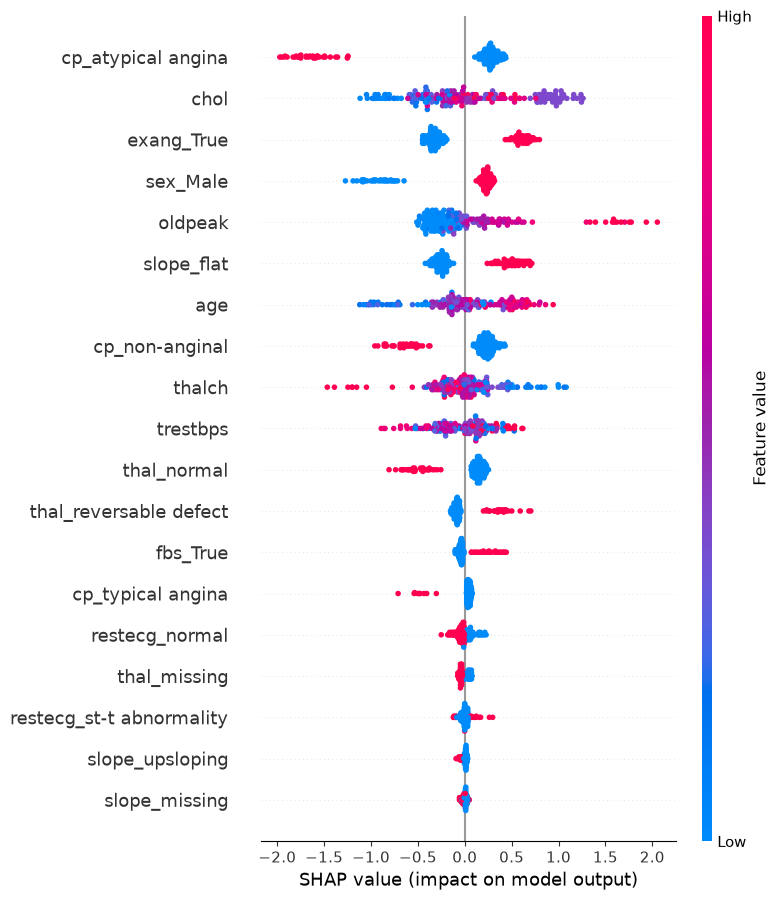

In [116]:
import shap

X_test_f = X_test.astype(float)   # avoids dtype problems with True/False columns

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test_f)

shap.summary_plot(shap_values, X_test_f)

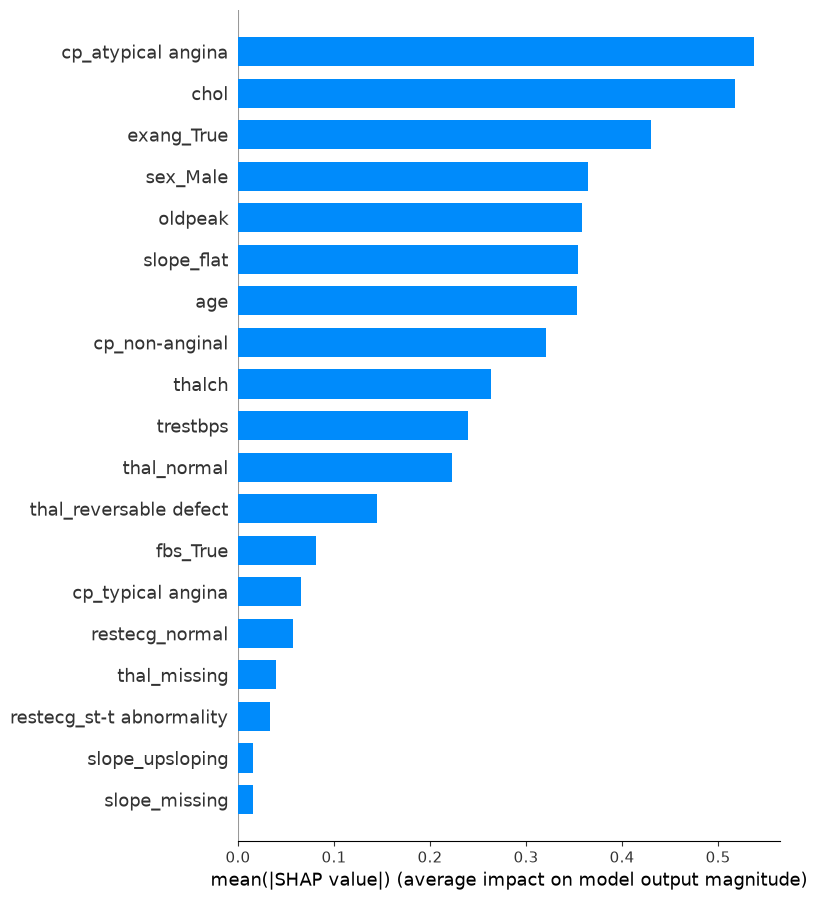

In [117]:
shap.summary_plot(shap_values, X_test_f, plot_type="bar")

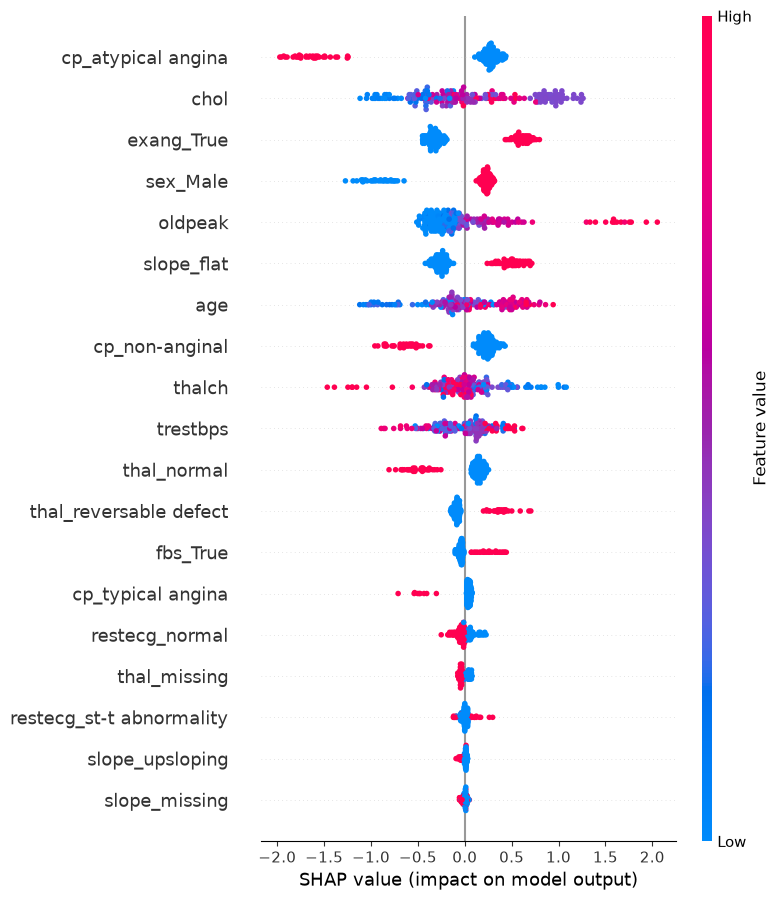

In [118]:
shap.summary_plot(shap_values, X_test_f)

In [119]:
for dropped in [[], ["chol"]]:
    Xtr = X_train.drop(columns=dropped)
    label = "without chol" if dropped else "with all features"
    for name, m in {"LogReg": logreg, "XGBoost": xgb}.items():
        auc = cross_val_score(m, Xtr, Y_train, cv=cv, scoring="roc_auc")
        rec = cross_val_score(m, Xtr, Y_train, cv=cv, scoring="recall")
        acc = cross_val_score(m, Xtr, Y_train, cv=cv, scoring="accuracy")
        print(f"{label} | {name}: acc {acc.mean():.3f}, AUC {auc.mean():.3f}, recall {rec.mean():.3f}")

with all features | LogReg: acc 0.806, AUC 0.875, recall 0.843
with all features | XGBoost: acc 0.807, AUC 0.871, recall 0.852
without chol | LogReg: acc 0.810, AUC 0.872, recall 0.852
without chol | XGBoost: acc 0.799, AUC 0.862, recall 0.850


## Model Results

**Task:** binary classification (0 = no heart disease, 1 = heart disease) on 920 patients, 80/20 stratified split (736 train, 184 test).

### 5-fold cross-validation (training set)

| Model | Accuracy | ROC-AUC | Recall |
|---|---|---|---|
| Logistic Regression | 0.806 | 0.875 | 0.843 |
| Random Forest | 0.813 | 0.871 | 0.862 |
| XGBoost | 0.807 | 0.871 | 0.852 |

### Test set (threshold 0.5)

| Model | Accuracy | ROC-AUC | Recall | Precision | Missed cases | False alarms |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.826 | 0.902 | 0.882 | 0.818 | 12 | 20 |
| Random Forest | 0.832 | 0.900 | 0.863 | 0.838 | 14 | 17 |
| XGBoost | 0.848 | 0.895 | 0.892 | 0.843 | 11 | 17 |

### Findings

- The three models perform about the same. Differences are smaller than the variation between cross-validation folds, and the test set has only 184 patients, so a gap of 2-4 patients is within noise.
- Features the models rely on match the EDA: `oldpeak`, `thalch`, `age`, chest pain type, exercise angina, ST slope and `thal`.
- `chol` has almost no predictive value here (172 values were recorded as 0 and imputed). Removing it did not hurt logistic regression and changed XGBoost within noise.
- Lowering the decision threshold from 0.5 to 0.4 raised recall of the logistic regression model from 0.882 to 0.902 at the cost of more false alarms (precision 0.818 to 0.773).

### Limitations

- Missing values were imputed before the train/test split, which may leak a small amount of information.
- Several columns had many missing values (`ca` dropped, `thal` and `slope` partly missing); missingness differs by hospital.
- The `dataset` (hospital) column was excluded on purpose.
- The data contains many more men than women, so results may not generalize.
- The decision threshold

In [120]:
import joblib

logreg.fit(X_train, Y_train)   

joblib.dump(logreg, "heart_model.joblib")
joblib.dump(X_train.columns.tolist(), "feature_columns.joblib")

['feature_columns.joblib']

In [121]:
loaded = joblib.load("heart_model.joblib")
cols = joblib.load("feature_columns.joblib")

print(len(cols), "features")
print("Same predictions as original:", (loaded.predict(X_test) == logreg.predict(X_test)).all())

19 features
Same predictions as original: True
